In [1]:
import pandas as pd
import numpy as np
import re
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

# Load the CSV file provided
csv_path = '/kaggle/input/datasets/ramakanthjogada/terferf/final-degradation.csv'
df = pd.read_csv(csv_path)

print("Columns found in CSV:", df.columns.tolist())
print("Total raw rows:", len(df))

# Define the target ground truth column and determine metric columns
gt_col = 'Ground_truth'
variant_cols = [col for col in df.columns if col not in ['Image_Id', gt_col]]

def clean_and_binarize(val):
    if pd.isna(val):
        return None
    # Convert to lowercase, strip spaces, and strip trailing periods/punctuation
    cleaned = str(val).strip().lower()
    cleaned = re.sub(r'[\.\!]+$', '', cleaned).strip()
    
    if cleaned in ['yes', 'y']:
        return 1
    elif cleaned in ['no', 'n']:
        return 0
    else:
        return None # Invalid value

# Prepare to accumulate results
metrics_summary = []

for col in variant_cols:
    # Align Ground_truth and Variant predictions, removing rows where either is invalid
    temp_df = pd.DataFrame({
        'y_true_raw': df[gt_col],
        'y_pred_raw': df[col]
    })
    
    temp_df['y_true'] = temp_df['y_true_raw'].apply(clean_and_binarize)
    temp_df['y_pred'] = temp_df['y_pred_raw'].apply(clean_and_binarize)
    
    # Drop any row containing None/invalid values (like '!!!!')
    clean_df = temp_df.dropna()
    
    y_true = clean_df['y_true'].astype(int).values
    y_pred = clean_df['y_pred'].astype(int).values
    
    if len(y_true) == 0:
        print(f"Warning: No valid rows remaining for column: {col}")
        continue
        
    # Calculate Confusion Matrix
    # labels=[0, 1] ensures the correct order: TN, FP, FN, TP
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    
    # Compute Metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    # Rates
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    
    metrics_summary.append({
        "Variant": col,
        "Valid_Rows": len(y_true),
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "FPR (False Positive Rate)": fpr,
        "FNR (False Negative Rate)": fnr
    })

# Convert to DataFrame and Display
df_metrics_output = pd.DataFrame(metrics_summary)
display(df_metrics_output)

# Export to Excel sheet
excel_path = 'evaluation_metrics-degradation-final.xlsx'
df_metrics_output.to_excel(excel_path, index=False)
print(f"Successfully exported final metric results to {excel_path}")

Columns found in CSV: ['Image_Id', 'Ground_truth', 'Original', 'Standard_Blur', 'Heavy_Blur', 'Occlusion', 'JPEG_Compression', 'Resizing']
Total raw rows: 989


,Variant,Valid_Rows,TP,TN,FP,FN,Accuracy,Precision,Recall,F1_Score,FPR (False Positive Rate),FNR (False Negative Rate)
0,Original,988,447,419,80,42,0.876518,0.848197,0.914110,0.879921,0.160321,0.085890
1,Standard_Blur,988,397,401,99,91,0.807692,0.800403,0.813525,0.806911,0.198000,0.186475
2,Heavy_Blur,989,321,376,124,168,0.704752,0.721348,0.656442,0.687366,0.248000,0.343558
3,Occlusion,986,385,426,71,104,0.822515,0.844298,0.787321,0.814815,0.142857,0.212679
4,JPEG_Compression,989,400,371,129,89,0.779575,0.756144,0.817996,0.785855,0.258000,0.182004
5,Resizing,989,342,362,138,147,0.711830,0.712500,0.699387,0.705882,0.276000,0.300613


Successfully exported final metric results to evaluation_metrics-degradation-final.xlsx


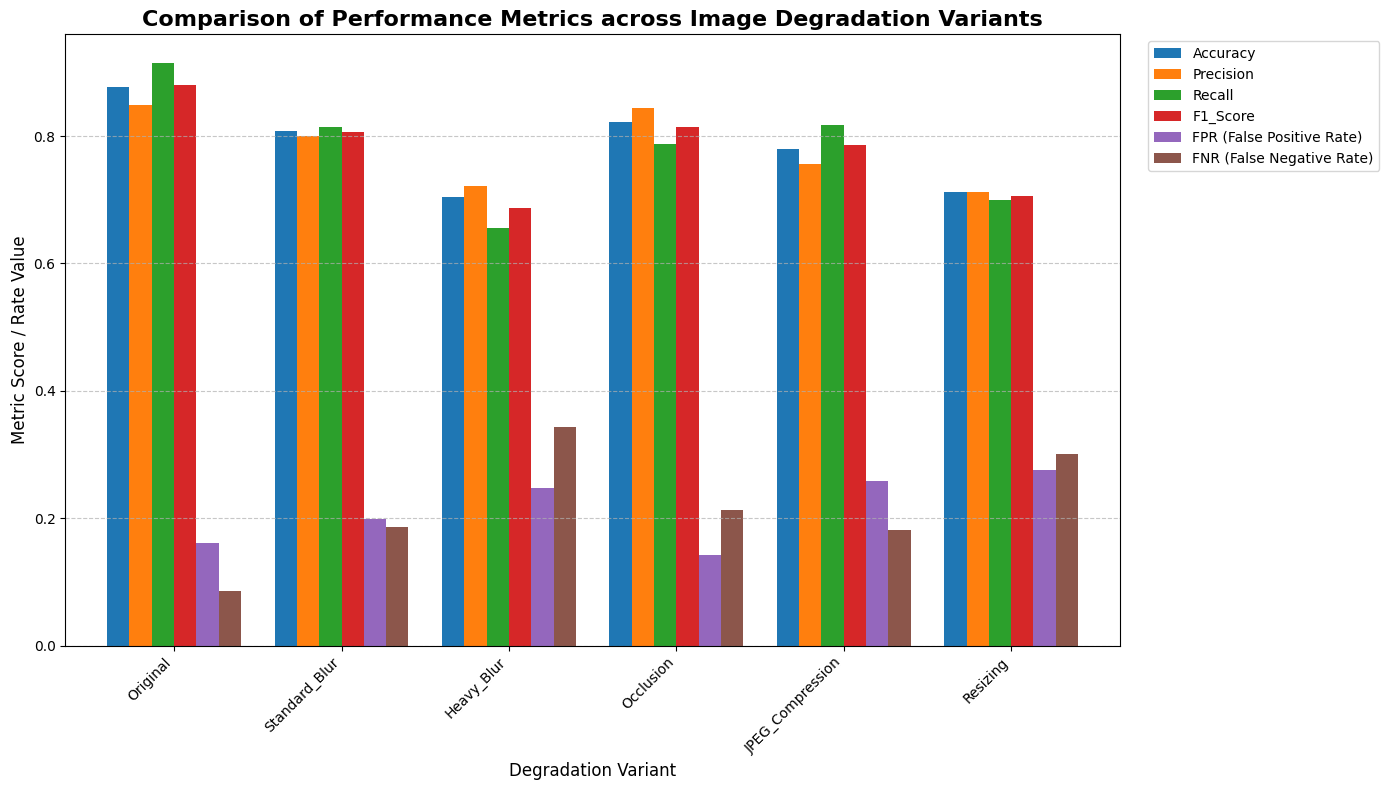

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the generated metrics
try:
    metrics_df = pd.read_excel('evaluation_metrics-degradation-final.xlsx')
except FileNotFoundError:
    # Fallback if the excel isn't written yet
    metrics_df = df_metrics_output.copy()

# 2. Select key performance rates/scores to visualize
plot_metrics = ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'FPR (False Positive Rate)', 'FNR (False Negative Rate)']

# Set the 'Variant' column as the index
plot_df = metrics_df.set_index('Variant')[plot_metrics]

# 3. Plot a grouped bar chart/histogram to compare metrics across different variants
fig, ax = plt.subplots(figsize=(14, 8))
plot_df.plot(kind='bar', ax=ax, width=0.8)

plt.title('Comparison of Performance Metrics across Image Degradation Variants', fontsize=16, fontweight='bold')
plt.xlabel('Degradation Variant', fontsize=12)
plt.ylabel('Metric Score / Rate Value', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

In [6]:

# Load the POPE final evaluation dataset
pope_csv_path = '/kaggle/input/datasets/ramakanthjogada/ajbiggcigc/diff-models-evals-on-POPE-final.csv'
df_pope = pd.read_csv(pope_csv_path)

print("Columns found in POPE CSV:", df_pope.columns.tolist())
print("Total raw rows in POPE:", len(df_pope))

# Define the target ground truth column and identify prediction columns
gt_col = 'Ground_truth'
variant_cols = [col for col in df_pope.columns if col not in ['Image_Id', gt_col]]

def clean_and_binarize(val):
    if pd.isna(val):
        return None
    # Convert to lowercase, strip spaces, and strip trailing periods/punctuation
    cleaned = str(val).strip().lower()
    cleaned = re.sub(r'[\.\!]+$', '', cleaned).strip()
    
    if cleaned in ['yes', 'y']:
        return 1
    elif cleaned in ['no', 'n']:
        return 0
    else:
        return None # Invalid value

# Prepare to accumulate POPE results
pope_metrics_summary = []

for col in variant_cols:
    # Align Ground_truth and Variant predictions, removing rows where either is invalid
    temp_df = pd.DataFrame({
        'y_true_raw': df_pope[gt_col],
        'y_pred_raw': df_pope[col]
    })
    
    temp_df['y_true'] = temp_df['y_true_raw'].apply(clean_and_binarize)
    temp_df['y_pred'] = temp_df['y_pred_raw'].apply(clean_and_binarize)
    
    # Drop any row containing None/invalid values (like '!!!!')
    clean_df = temp_df.dropna()
    
    y_true = clean_df['y_true'].astype(int).values
    y_pred = clean_df['y_pred'].astype(int).values
    
    if len(y_true) == 0:
        print(f"Warning: No valid rows remaining for column: {col}")
        continue
        
    # Calculate Confusion Matrix (labels=[0, 1] ensures order: TN, FP, FN, TP)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    
    # Compute Metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    # Rates
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    
    pope_metrics_summary.append({
        "Variant": col,
        "Valid_Rows": len(y_true),
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "FPR (False Positive Rate)": fpr,
        "FNR (False Negative Rate)": fnr
    })

# Convert to DataFrame and Display
df_pope_metrics = pd.DataFrame(pope_metrics_summary)
display(df_pope_metrics)

# Export to Excel sheet
pope_excel_path = 'evaluation_metrics-pope-final-diff-models.xlsx'
df_pope_metrics.to_excel(pope_excel_path, index=False)
print(f"Successfully exported POPE metric results to {pope_excel_path}")

Columns found in POPE CSV: ['Unnamed: 0', 'Image_Id', 'Ground_truth', 'Qwen-2B', 'Qwen-3B', 'Smol-2.2B']
Total raw rows in POPE: 989


,Variant,Valid_Rows,TP,TN,FP,FN,Accuracy,Precision,Recall,F1_Score,FPR (False Positive Rate),FNR (False Negative Rate)
0,Qwen-2B,989,466,394,106,23,0.869565,0.814685,0.952965,0.878417,0.212000,0.047035
1,Qwen-3B,988,447,419,80,42,0.876518,0.848197,0.914110,0.879921,0.160321,0.085890
2,Smol-2.2B,989,433,387,113,56,0.829120,0.793040,0.885481,0.836715,0.226000,0.114519


Successfully exported POPE metric results to evaluation_metrics-pope-final-diff-models.xlsx


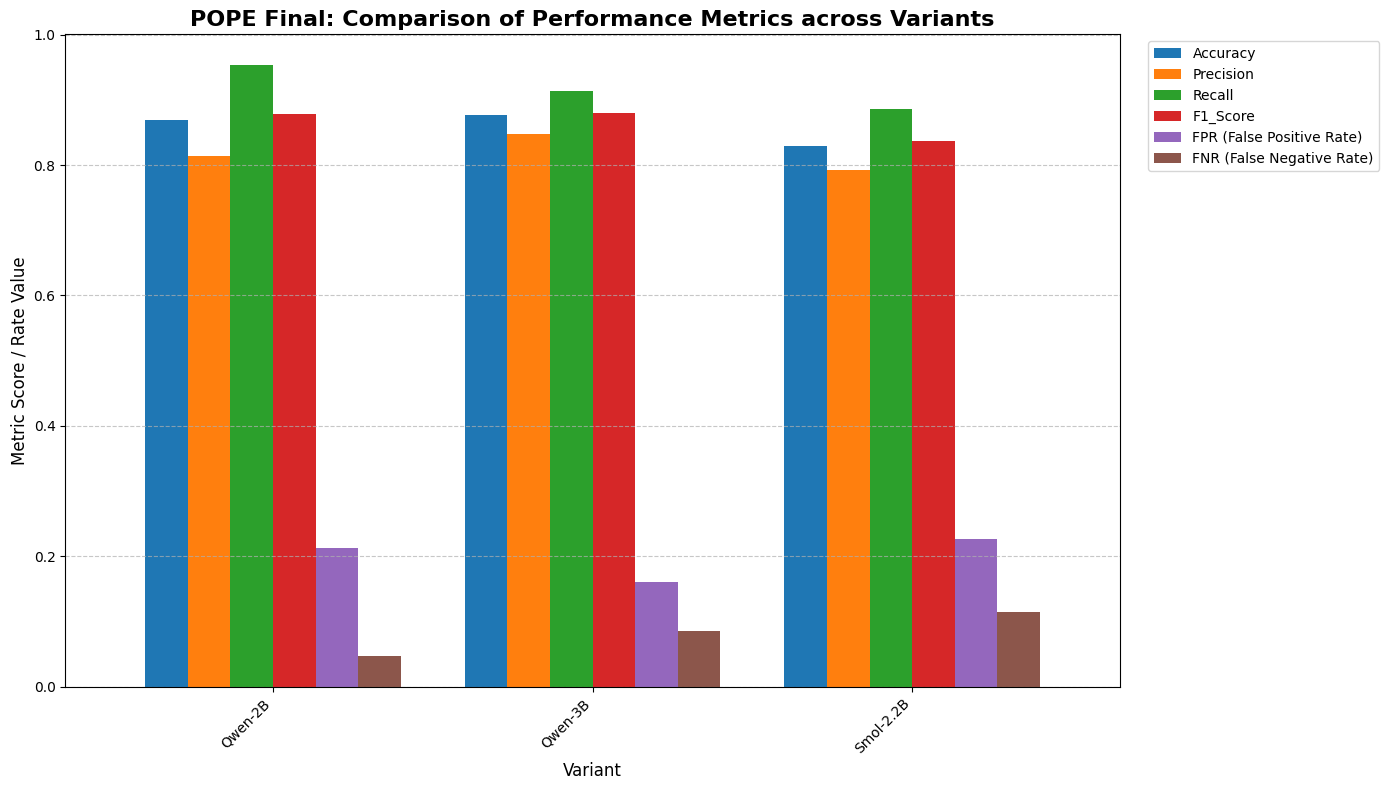

In [7]:


# 1. Load the generated metrics
try:
    pope_plot_df = pd.read_excel('evaluation_metrics-pope-final.xlsx')
except FileNotFoundError:
    pope_plot_df = df_pope_metrics.copy()

# 2. Select key performance rates/scores to visualize
plot_metrics = ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'FPR (False Positive Rate)', 'FNR (False Negative Rate)']

# Set the 'Variant' column as the index
pope_plot_df = pope_plot_df.set_index('Variant')[plot_metrics]

# 3. Plot a grouped bar chart/histogram to compare metrics across different variants
fig, ax = plt.subplots(figsize=(14, 8))
pope_plot_df.plot(kind='bar', ax=ax, width=0.8)

plt.title('POPE Final: Comparison of Performance Metrics across Variants', fontsize=16, fontweight='bold')
plt.xlabel('Variant', fontsize=12)
plt.ylabel('Metric Score / Rate Value', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()